In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel("../clean_coast_data.xlsx")

In [2]:
df.sort_values(by= ['Distance from gaza','hifa_port_dis'], inplace=True)

In [3]:
gaza_distance = df.groupby(['Distance from gaza']).mean()[['test_result']]
haifa_distance = df.groupby(['hifa_port_dis']).mean()[['test_result']]

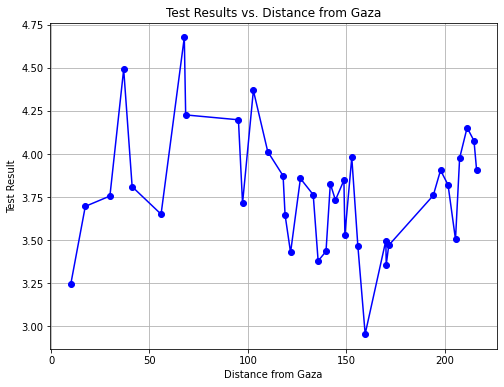

In [4]:
x = gaza_distance.index
y = gaza_distance['test_result']

plt.figure(figsize=(8, 6))  # Adjust the figure size as needed
plt.plot(x, y, marker='o', linestyle='-', color='blue')
plt.title('Test Results vs. Distance from Gaza')
plt.xlabel('Distance from Gaza')
plt.ylabel('Test Result')

plt.grid(True)
plt.show()

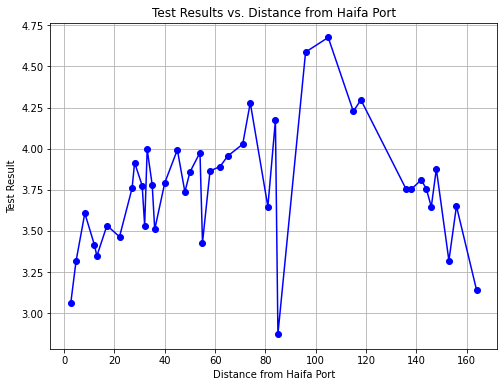

In [5]:
x = haifa_distance.index
y = haifa_distance['test_result']

plt.figure(figsize=(8, 6))  # Adjust the figure size as needed
plt.plot(x, y, marker='o', linestyle='-', color='blue')
plt.title('Test Results vs. Distance from Haifa Port')
plt.xlabel('Distance from Haifa Port')
plt.ylabel('Test Result')

plt.grid(True)
plt.show()

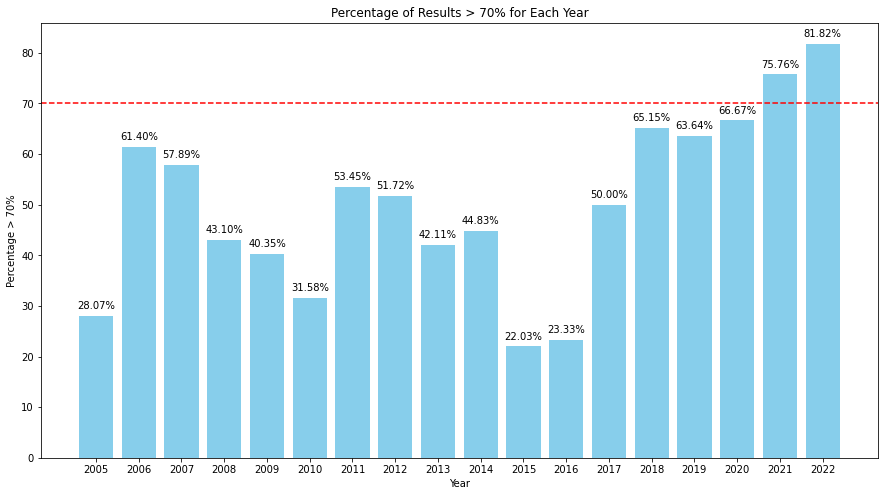

In [34]:
a = df[['year','coast_name','test_result_num']]
# Filter rows where 'test_result_num' is between 0 and 5
filtered_df = a[(a['test_result_num'] >= 0) & (a['test_result_num'] <= 5)]

percentage_df = (filtered_df.groupby(['year', 'coast_name'])
                 .size()
                 .div(df.groupby(['year', 'coast_name']).size())
                 .mul(100)
                 .reset_index(name='percentage_0_5'))
# print(percentage_df)
# Calculate the percentage of results higher than 70% for each year
result_df = (percentage_df.groupby('year')['percentage_0_5']
              .apply(lambda x: (x > 70).mean() * 100)
              .reset_index(name='percentage_gt_70'))
# result_df
result_df['percentage_gt_70'] = result_df['percentage_gt_70'].apply(lambda x: round(x, 2))
result_df['year'] = result_df['year'].apply(lambda x: str(x))

plt.figure(figsize=(15, 8))
plt.bar(result_df['year'], result_df['percentage_gt_70'], color='skyblue')
for i, percentage in enumerate(result_df['percentage_gt_70']):
    plt.text(result_df['year'][i], percentage + 1, f'{percentage:.2f}%', ha='center', va='bottom')
plt.axhline(y=70, color='red', linestyle='--', label='Threshold (70%)')

plt.xlabel('Year')
plt.ylabel('Percentage > 70%')
plt.title('Percentage of Results > 70% for Each Year')
plt.show()

     year         authority  percentage_0_5
0    2005              אילת       42.307692
1    2005             אשדוד       52.173913
2    2005            אשקלון       27.848101
3    2005             בת ים       77.777778
4    2005       ג'סר א-זרקא       80.000000
..    ...               ...             ...
347  2022               עכו       93.478261
348  2022           עמק חפר       78.260870
349  2022          קריית ים       73.913043
350  2022  רשות הטבע והגנים       82.608696
351  2022       תל אביב-יפו       91.304348

[352 rows x 3 columns]


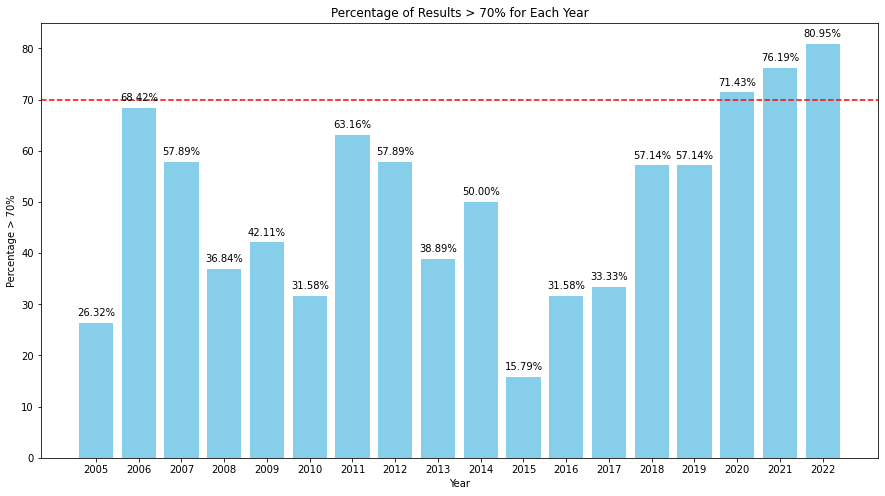

In [9]:
authorities = pd.read_excel("../authorities.xlsx")
authorities = authorities[['coast_name','local_authority']]

# Create a dictionary mapping coast_name to local_authority from DataFrame 'a'
coast_authority_map = dict(zip(authorities['coast_name'], authorities['local_authority']))

# Add 'authority' column to DataFrame 'b' based on the mapping
df['authority'] = df['coast_name'].map(coast_authority_map)
df.loc[((df.coast_name == 'חוף המגדלור') & (df.Area == 'Center')),'authority'] = 'תל אביב-יפו'
df.loc[((df.coast_name == 'חוף המגדלור') & (df.Area == 'Eilat')),'authority'] = 'אילת'

a = df[['authority','year','test_result_num']]
# Filter rows where 'test_result_num' is between 0 and 5
filtered_df = a[(a['test_result_num'] >= 0) & (a['test_result_num'] <= 5)]

percentage_df = (filtered_df.groupby(['year', 'authority'])
                 .size()
                 .div(df.groupby(['year', 'authority']).size())
                 .mul(100)
                 .reset_index(name='percentage_0_5'))
print(percentage_df)
# Calculate the percentage of results higher than 70% for each year
result_df = (percentage_df.groupby('year')['percentage_0_5']
              .apply(lambda x: (x > 70).mean() * 100)
              .reset_index(name='percentage_gt_70'))
result_df
result_df['percentage_gt_70'] = result_df['percentage_gt_70'].apply(lambda x: round(x, 2))
result_df['year'] = result_df['year'].apply(lambda x: str(x))

plt.figure(figsize=(15, 8))
plt.bar(result_df['year'], result_df['percentage_gt_70'], color='skyblue')
for i, percentage in enumerate(result_df['percentage_gt_70']):
    plt.text(result_df['year'][i], percentage + 1, f'{percentage:.2f}%', ha='center', va='bottom')
plt.axhline(y=70, color='red', linestyle='--', label='Threshold (70%)')

plt.xlabel('Year')
plt.ylabel('Percentage > 70%')
plt.title('Percentage of Results > 70% for Each Year')
plt.show()